# 04 · Backtest: la cuarentena como experimento natural

*Segundos contra vidas* · Hackathon de Datos 2026 · ITM

**Pregunta:** cuando Medellín se vació (20 mar – 31 ago 2020) y se aceleró, ¿murieron más víctimas de las que se esperaban según quiénes fueron?

La exploración mostró que la letalidad subió (0,78% → 0,95%), pero sin corregir por la composición: en la cuarentena hubo menos peatones, más motos y otras horas. Aquí:
1. **Contrafactual:** el modelo logístico validado (D24), entrenado con 2014–2019, predice los muertos esperados según el perfil de cada víctima. Se compara con los observados (**O/E**).
2. **Placebo:** lo mismo para los mismos meses de 2019, sin cuarentena. Debe dar O/E ≈ 1.
3. **Exponente implícito:** con el aumento de velocidad de Google Traffic, ¿qué exponente implica el exceso? Se compara con Nilsson.
4. **Explicación rival:** hospitales saturados (capa del Distrito).

Es a nivel ciudad: no depende de los corredores. Cada parte: código → conclusión → decisión.

## 0 · Configuración

In [1]:
import os, sys, unicodedata, re
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from src.descarga import leer
from src.velocidad import tiempo_viaje_gt

pd.set_option("display.max_columns", 40)
Path("data/processed").mkdir(parents=True, exist_ok=True)

INICIO, FIN = pd.Timestamp("2020-03-20"), pd.Timestamp("2020-08-31")      # cuarentena (igual que en 01 y 02)
RAPIDAS = ["AV_REGIONAL", "AUT_NORTE", "AUT_SUR", "AV_PALMAS"]            # D18
print("Proyecto:", raiz)

Proyecto: C:\Users\crist\Documents\segundos-contra-vidas


In [2]:
# Nombres de columnas uniformes: minúscula, sin tildes, con guion bajo
def _arreglar_texto(s):
    for codif in ("latin-1", "cp1252"):
        try:
            return s.encode(codif).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return s

def normalizar_columnas(df):
    nuevas = []
    for c in df.columns:
        c = unicodedata.normalize("NFKD", _arreglar_texto(str(c))).encode("ascii", "ignore").decode()
        nuevas.append(re.sub(r"[^0-9a-z]+", "_", c.lower()).strip("_"))
    df.columns = nuevas
    return df

def misma_ventana(fechas, ano):
    """True si la fecha cae entre el 20 de marzo y el 31 de agosto del año indicado."""
    return fechas.between(INICIO.replace(year=ano), FIN.replace(year=ano))

def o_sobre_e(obs, esp):
    """O/E con IC 95% exacto de Poisson para O, y p de la prueba O ~ Poisson(E)."""
    lo = stats.chi2.ppf(0.025, 2 * obs) / 2 if obs > 0 else 0.0
    hi = stats.chi2.ppf(0.975, 2 * (obs + 1)) / 2
    p = min(1.0, 2 * min(stats.poisson.cdf(obs, esp), stats.poisson.sf(obs - 1, esp)))
    return {"observados": int(obs), "esperados": esp, "O/E": obs / esp,
            "IC95_inf": lo / esp, "IC95_sup": hi / esp, "p": p}

## 1 · ¿Cuánto se aceleró la ciudad?

#### 1.1 Velocidad en la cuarentena frente a los mismos meses de 2017–2019 (Google Traffic)
Se comparan las mismas fechas del año (20 mar – 31 ago) para no mezclar la estacionalidad. La razón se calcula por corredor y luego se promedia en escala log (media geométrica).

In [3]:
tv = tiempo_viaje_gt()
tv["fecha"] = pd.to_datetime(tv["fecha"])
tv["ano"] = tv["fecha"].dt.year
tv = tv[tv["velocidad_gt_kmh"] > 0]

en_ventana = pd.concat([misma_ventana(tv["fecha"], a) for a in range(2017, 2021)], axis=1).any(axis=1)
v = tv[en_ventana].assign(periodo=np.where(tv.loc[en_ventana, "ano"] == 2020, "cuarentena", "2017_2019"))
por_corr = v.groupby(["corredor_id", "periodo"])["velocidad_gt_kmh"].mean().unstack()
por_corr["razon"] = por_corr["cuarentena"] / por_corr["2017_2019"]
por_corr["tipo"] = np.where(por_corr.index.isin(RAPIDAS), "vías rápidas", "arterias")

def media_geo(s):
    return float(np.exp(np.log(s).mean()))

RAZON = {"todos": media_geo(por_corr["razon"]),
         "vías rápidas": media_geo(por_corr.loc[por_corr["tipo"] == "vías rápidas", "razon"]),
         "arterias": media_geo(por_corr.loc[por_corr["tipo"] == "arterias", "razon"])}
for k, r in RAZON.items():
    print(f"Velocidad en la cuarentena, {k}: ×{r:.3f} ({(r - 1) * 100:+.0f}%)")
por_corr.round(2).sort_values("razon", ascending=False)

Velocidad en la cuarentena, todos: ×1.305 (+31%)
Velocidad en la cuarentena, vías rápidas: ×1.237 (+24%)
Velocidad en la cuarentena, arterias: ×1.341 (+34%)


periodo,2017_2019,cuarentena,razon,tipo
corredor_id,,,,
AV_POBLADO,20.11,31.29,1.56,arterias
AV_FERROCARRIL,18.59,27.51,1.48,arterias
AV_80,21.60,29.33,1.36,arterias
CL_30,20.03,27.18,1.36,arterias
AUT_SUR,44.18,58.85,1.33,vías rápidas
AV_ORIENTAL,13.39,17.65,1.32,arterias
AV_33,28.36,35.82,1.26,arterias
AUT_NORTE,44.85,56.29,1.26,vías rápidas
AV_GUAYABAL,32.31,39.44,1.22,arterias


### Conclusión
- **Durante la cuarentena la ciudad fue un 31% más rápida** que en las mismas fechas de 2017–2019, como media geométrica de los 12 corredores. Todos los corredores se aceleraron: el que menos, Las Palmas (+16%), y el que más, El Poblado (+56%).
- **Las arterias se aceleraron más que las vías rápidas (+34% contra +24%).** Las vías rápidas ya iban cerca de su velocidad libre (la Regional, a 53 km/h). En cambio, a las arterias las frenaba la congestión, y al vaciarse la ciudad ganaron más.
- **En las vías rápidas la cuarentena llevó la velocidad por encima de 50:** Regional 64, Autopista Sur 59 y Autopista Norte 56 km/h. Las arterias, aun vacías, siguieron entre 18 y 39 km/h.
- Estas cifras son un poco menores que las de la exploración (+29% y +45%), porque allá se comparaban meses pico de 2020 contra años completos. Esta comparación, con las mismas fechas del año, es la correcta.

### Decisión
- La razón principal para el exponente implícito (parte 3) es **r = 1,305** (todos los corredores). Las razones de las vías rápidas (1,24) y de las arterias (1,34) van como sensibilidad.
- En el pitch se usa **"+31%"** como la cifra de aceleración de la cuarentena, en lugar del +29% y +45% de la exploración.

## 2 · Contrafactual: ¿murieron más de los esperados?

#### 2.1 Víctimas (misma preparación que el notebook 02, D12)

In [4]:
vic = normalizar_columnas(leer("victimas_medata"))
vic = vic[vic["ano"].notna()].copy()

vic["fecha"] = pd.to_datetime(vic["fecha_incidente"], dayfirst=True, errors="coerce")
vic["hora"] = pd.to_numeric(vic["hora"], errors="coerce")
vic["edad"] = pd.to_numeric(vic["edad"], errors="coerce")
vic["ano"] = vic["ano"].astype(int)
vic["muerto"] = (vic["gravedad_victima"] == "Muertos").astype(int)
vic["condicion"] = vic["condicion"].replace({"Acompañante de Motocicleta": "Acompañante de motocicleta"})
vic["actor"] = vic["condicion"].replace({"Motociclista": "Moto", "Acompañante de motocicleta": "Moto"})

vic["grupo_edad"] = pd.cut(vic["edad"], [0, 19, 29, 44, 59, 120], labels=["<20", "20-29", "30-44", "45-59", "60+"])
vic["franja"] = pd.cut(vic["hora"], [-1, 5, 17, 23], labels=["madrugada (0-5)", "dia (6-17)", "noche (18-23)"])
vic["fin_de_semana"] = (vic["fecha"].dt.dayofweek >= 5).astype(int)

usadas = ["muerto", "actor", "grupo_edad", "sexo", "franja", "fin_de_semana", "fecha"]
m = vic[vic["sexo"].isin(["M", "F"])].dropna(subset=usadas)[usadas + ["ano", "hora"]].copy()
print(f"Víctimas para el backtest: {len(m):,} · muertos: {m['muerto'].sum():,}")
print(f"De ellas en la cuarentena: {m['fecha'].between(INICIO, FIN).sum():,}")

Víctimas para el backtest: 230,157 · muertos: 1,887
De ellas en la cuarentena: 7,247


#### 2.2 Muertos observados contra esperados
El modelo es el de la validación del notebook 02 (sin año ni cuarentena, entrenado con 2014–2019). Si **O/E > 1**, murieron más víctimas de las que explica su perfil.

In [5]:
formula = ("muerto ~ C(actor, Treatment('Moto')) + C(grupo_edad, Treatment('20-29'))"
           " + C(sexo, Treatment('M')) + C(franja, Treatment('dia (6-17)')) + fin_de_semana")
modelo = smf.logit(formula, data=m[m["ano"] <= 2019]).fit(disp=0)

periodos = {
    "2020 antes (1 ene – 19 mar)":     m["fecha"].between("2020-01-01", "2020-03-19"),
    "Cuarentena (20 mar – 31 ago)":    m["fecha"].between(INICIO, FIN),
    "Reapertura (sep – dic 2020)":     m["fecha"].between("2020-09-01", "2020-12-31"),
    "2021 (ene – sep)":                m["fecha"].between("2021-01-01", "2021-09-30"),
}
filas = []
for nombre, filtro in periodos.items():
    d = m[filtro]
    filas.append({"periodo": nombre, "victimas": len(d), **o_sobre_e(d["muerto"].sum(), modelo.predict(d).sum())})
oe = pd.DataFrame(filas).set_index("periodo")
oe.round(3)

,victimas,observados,esperados,O/E,IC95_inf,IC95_sup,p
periodo,,,,,,,
2020 antes (1 ene – 19 mar),7407,49,64.132,0.764,0.565,1.010,0.060
Cuarentena (20 mar – 31 ago),7247,70,59.003,1.186,0.925,1.499,0.177
Reapertura (sep – dic 2020),8435,76,69.468,1.094,0.862,1.369,0.463
2021 (ene – sep),20390,162,160.361,1.010,0.861,1.178,0.918


#### 2.3 Placebos: los mismos meses de 2015 a 2019
Para cada año sin cuarentena se entrena con los demás años de 2014–2019 y se predice su 20 mar – 31 ago. Si el método está bien, estos O/E rondan 1: muestran cuánto varía el O/E en un año normal.

In [6]:
placebos, mods = [], {}
for ano in range(2015, 2020):
    mods[ano] = smf.logit(formula, data=m[(m["ano"] <= 2019) & (m["ano"] != ano)]).fit(disp=0)
    d = m[misma_ventana(m["fecha"], ano)]
    placebos.append({"periodo": f"Placebo {ano}", "victimas": len(d),
                     **o_sobre_e(d["muerto"].sum(), mods[ano].predict(d).sum())})
placebo = pd.DataFrame(placebos).set_index("periodo")
print(f"Rango de O/E en años normales: {placebo['O/E'].min():.2f} a {placebo['O/E'].max():.2f}")
print(f"¿La cuarentena queda por encima de todos los placebos? {oe.loc['Cuarentena (20 mar – 31 ago)', 'O/E'] > placebo['O/E'].max()}")
placebo.round(3)

Rango de O/E en años normales: 0.89 a 1.20
¿La cuarentena queda por encima de todos los placebos? False


,victimas,observados,esperados,O/E,IC95_inf,IC95_sup,p
periodo,,,,,,,
Placebo 2015,14526,143,119.610,1.196,1.008,1.408,0.041
Placebo 2016,15220,127,121.024,1.049,0.875,1.249,0.611
Placebo 2017,14177,106,110.092,0.963,0.788,1.165,0.743
Placebo 2018,13257,96,108.011,0.889,0.720,1.085,0.266
Placebo 2019,13509,117,116.770,1.002,0.829,1.201,1.000


#### 2.4 Por actor (moto y peatón)
La composición cambió en la cuarentena (menos peatones), por eso se mira cada actor por separado (D19).

In [7]:
filas = []
for actor in ["Moto", "Peatón"]:
    obs = esp = n = 0
    for ano, mod in mods.items():
        d = m[misma_ventana(m["fecha"], ano) & (m["actor"] == actor)]
        obs, esp, n = obs + d["muerto"].sum(), esp + mod.predict(d).sum(), n + len(d)
    filas.append({"actor": actor, "periodo": "Placebos 2015–2019", "victimas": n, **o_sobre_e(obs, esp)})
    d = m[m["fecha"].between(INICIO, FIN) & (m["actor"] == actor)]
    filas.append({"actor": actor, "periodo": "Cuarentena 2020", "victimas": len(d),
                  **o_sobre_e(d["muerto"].sum(), modelo.predict(d).sum())})
oe_actor = pd.DataFrame(filas).set_index(["actor", "periodo"])
oe_actor.round(3)

victimas  observados  esperados    O/E  IC95_inf  \
actor  periodo                                                                
Moto   Placebos 2015–2019     53553         271    268.200  1.010     0.894   
       Cuarentena 2020         5738          36     30.401  1.184     0.829   
Peatón Placebos 2015–2019      9497         269    255.608  1.052     0.930   
       Cuarentena 2020          814          29     22.423  1.293     0.866   

                           IC95_sup      p  
actor  periodo                              
Moto   Placebos 2015–2019     1.138  0.880  
       Cuarentena 2020        1.639  0.352  
Peatón Placebos 2015–2019     1.186  0.418  
       Cuarentena 2020        1.857  0.206

#### 2.5 Sensibilidad: solo de 6:00 a 20:00
Es la ventana que mide Google Traffic. Así la velocidad y las víctimas cubren las mismas horas.

In [8]:
dia = m["hora"].between(6, 20)
obs = sum(m[misma_ventana(m["fecha"], a) & dia]["muerto"].sum() for a in mods)
esp = sum(mod.predict(m[misma_ventana(m["fecha"], a) & dia]).sum() for a, mod in mods.items())
cuar_dia = m[m["fecha"].between(INICIO, FIN) & dia]
sens = pd.DataFrame([
    {"periodo": "Placebos 2015–2019 · 6–20 h", **o_sobre_e(obs, esp)},
    {"periodo": "Cuarentena · 6–20 h", **o_sobre_e(cuar_dia["muerto"].sum(), modelo.predict(cuar_dia).sum())},
]).set_index("periodo")
sens.round(3)

,observados,esperados,O/E,IC95_inf,IC95_sup,p
periodo,,,,,,
Placebos 2015–2019 · 6–20 h,398,416.725,0.955,0.864,1.054,0.373
Cuarentena · 6–20 h,48,44.684,1.074,0.792,1.424,0.659


#### 2.6 Gráfica

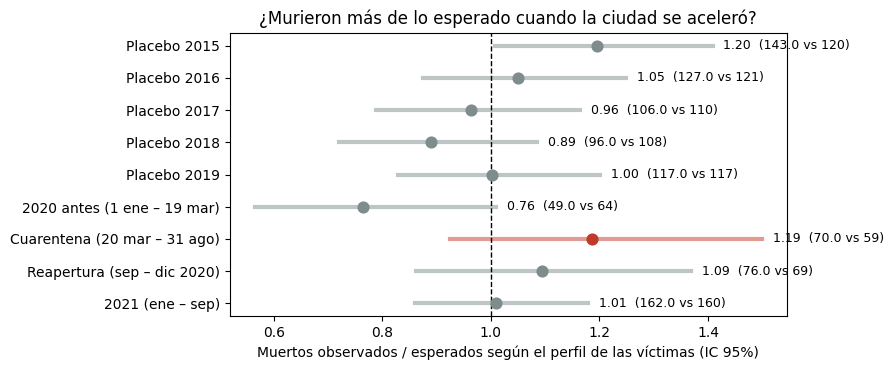

In [9]:
g = pd.concat([placebo, oe])
fig, ax = plt.subplots(figsize=(9, 3.8))
colores = ["#7f8c8d" if ("Placebo" in i or "Cuarentena" not in i) else "#c0392b" for i in g.index]
for k, (i, r) in enumerate(g.iterrows()):
    ax.plot([r["IC95_inf"], r["IC95_sup"]], [k, k], color=colores[k], lw=3, alpha=0.5)
    ax.scatter(r["O/E"], k, color=colores[k], s=60, zorder=3)
    ax.text(r["IC95_sup"] + 0.02, k, f"{r['O/E']:.2f}  ({r['observados']} vs {r['esperados']:.0f})", va="center", fontsize=9)
ax.axvline(1, ls="--", color="black", lw=1)
ax.set_yticks(range(len(g)), g.index); ax.invert_yaxis()
ax.set_xlabel("Muertos observados / esperados según el perfil de las víctimas (IC 95%)")
ax.set_title("¿Murieron más de lo esperado cuando la ciudad se aceleró?")
plt.tight_layout(); plt.show()

### Conclusión
- **La cuarentena no muestra un exceso de muertes distinguible de un año normal.** Corrigiendo por el perfil de las víctimas (actor, edad, sexo, franja, fin de semana), murieron 70 donde se esperaban 59: **O/E = 1,19 (IC 95% 0,93–1,50; p = 0,18)**.
- **Los placebos confirman que ese exceso cabe en la variación normal:** en los mismos meses de 2015–2019 el O/E fue de 0,89 a 1,20 (2015 = 1,20). Además, los placebos varían más de lo que indica el IC de Poisson (2015 sale con p = 0,04 sin cuarentena), así que la referencia correcta es el rango de los placebos.
- **Por actor, el exceso va en la dirección esperada, pero no es significativo:** moto 1,18 (0,83–1,64) y peatón 1,29 (0,87–1,86). Los placebos por actor dan ≈ 1 (1,01 y 1,05).
- **De día (6–20 h) no hay exceso: O/E = 1,07 (0,79–1,42).** La diferencia está de noche: 22 muertos contra 14 esperados (O/E ≈ 1,54; p ≈ 0,07), justo las horas que Google Traffic no mide. Es una pista, no una prueba.
- La comparación bruta de la exploración (+22% de letalidad, p = 0,12) exageraba el efecto, porque no corregía la composición de las víctimas.

### Decisión
- **D19 se ajusta:** la cuarentena **no** se presenta como evidencia de que la velocidad aumentó la letalidad. Se presenta como un experimento natural cuyo resultado va en la dirección esperada, pero no se distingue de la variación de un año normal.
- El hallazgo 7 del pitch se reescribe sin las cifras brutas (+31% moto, +37% peatón).
- El exceso nocturno se reporta como hipótesis, en coherencia con D20 (riesgo nocturno aparte).

## 3 · ¿Qué exponente implica?
Nilsson: los siniestros con heridos crecen con la velocidad a la ~2 y los mortales a la ~4. Entonces la proporción de víctimas que muere crece a la **~2** (4 − 2).

Si la velocidad se multiplicó por *r*, Nilsson predice **O/E ≈ r²**. Al revés, el exponente implícito de Medellín es **β = ln(O/E) / ln(r)**.

In [10]:
def implicito(fila, r):
    return {"β implícito": np.log(fila["O/E"]) / np.log(r),
            "β IC95_inf": np.log(max(fila["IC95_inf"], 1e-9)) / np.log(r),
            "β IC95_sup": np.log(fila["IC95_sup"]) / np.log(r),
            "O/E observado": fila["O/E"], "O/E si Nilsson (r²)": r ** 2}

c = oe.loc["Cuarentena (20 mar – 31 ago)"]
c_dia = sens.loc["Cuarentena · 6–20 h"]
filas = [{"víctimas": "todas", "velocidad": k, "r": r, **implicito(c, r)} for k, r in RAZON.items()]
filas += [{"víctimas": "6–20 h", "velocidad": "todos", "r": RAZON["todos"], **implicito(c_dia, RAZON["todos"])}]
filas += [{"víctimas": a, "velocidad": "todos", "r": RAZON["todos"],
           **implicito(oe_actor.loc[(a, "Cuarentena 2020")], RAZON["todos"])} for a in ["Moto", "Peatón"]]
exp_impl = pd.DataFrame(filas).set_index(["víctimas", "velocidad"])
exp_impl.round(2)

r  β implícito  β IC95_inf  β IC95_sup  \
víctimas velocidad                                                 
todas    todos         1.31         0.64       -0.29        1.52   
         vías rápidas  1.24         0.80       -0.37        1.90   
         arterias      1.34         0.58       -0.27        1.38   
6–20 h   todos         1.31         0.27       -0.87        1.33   
Moto     todos         1.31         0.63       -0.70        1.85   
Peatón   todos         1.31         0.96       -0.54        2.32   

                       O/E observado  O/E si Nilsson (r²)  
víctimas velocidad                                         
todas    todos                  1.19                 1.70  
         vías rápidas           1.19                 1.53  
         arterias               1.19                 1.80  
6–20 h   todos                  1.07                 1.70  
Moto     todos                  1.18                 1.70  
Peatón   todos                  1.29                 1.70

### Conclusión
- Con la velocidad +31% (r = 1,305), el exceso observado implica un **exponente para la letalidad de 0,64 (IC 95% −0,29 a 1,52)**. Todos los intervalos incluyen el 0: no se puede descartar que la letalidad no haya respondido a la velocidad.
- **Nilsson (β = 2; O/E = r² = 1,70) queda fuera del intervalo en casi todos los escenarios:** con todos los corredores (máx. 1,52), con las arterias (1,38), de día (1,33) y, por poco, con las vías rápidas (1,90) y en motos (1,85).
- **La excepción son los peatones:** β = 0,96 (−0,54 a 2,32), compatible con Nilsson. Es coherente con D23: la velocidad pesa más sobre los más vulnerables.
- A nivel ciudad, la letalidad respondió a la velocidad menos de lo que predice Nilsson.
- Limitación: la velocidad sale de 12 corredores de Google Traffic y de 6 a 20 h, mientras que las víctimas son de toda la ciudad y de todas las horas. Con solo 70 muertos en la cuarentena, los intervalos son anchos.

### Decisión
- En el Monte Carlo, el efecto de la velocidad sobre la letalidad **no se fija en Nilsson (2)**: va como sensibilidad entre 0 y 2. El efecto principal sale del exponente de incidentes graves del notebook 03.
- Para peatones, Nilsson (2) sí es un valor defendible dentro de la sensibilidad.

## 4 · Explicación rival: ¿hospitales saturados?
Si en la cuarentena murieron más heridos porque los hospitales estaban llenos, debería subir la proporción de muertes en **centros asistenciales**. Las muertes **en la vía** no dependen del hospital.

La capa del Distrito empieza en 2019: se comparan los mismos meses (20 mar – 31 ago) de cada año.

In [11]:
mort = normalizar_columnas(leer("mortalidad_distrito"))
mort["fecha"] = pd.to_datetime(mort["fecha_ocurrencia"], dayfirst=True, errors="coerce")
mort["ano"] = mort["fecha"].dt.year
mort["lugar"] = mort["lugar_inspeccion"].astype(str).str.strip().replace(
    {"Vía Pública": "en la vía", "Centro Asistencial": "centro asistencial"})
mort.loc[~mort["lugar"].isin(["en la vía", "centro asistencial"]), "lugar"] = "otro / sin dato"

ventana = pd.concat([misma_ventana(mort["fecha"], a) for a in range(2019, 2025)], axis=1).any(axis=1)
w = mort[ventana]
lugar = pd.crosstab(w["ano"], w["lugar"])
lugar["total"] = lugar.sum(axis=1)
lugar["% en centro asistencial"] = (lugar.get("centro asistencial", 0) / lugar["total"] * 100).round(1)

cuar = lugar.loc[2020]
resto = lugar.drop(index=2020)[["centro asistencial", "total"]].sum()
tabla = [[cuar["centro asistencial"], cuar["total"] - cuar["centro asistencial"]],
         [resto["centro asistencial"], resto["total"] - resto["centro asistencial"]]]
_, p_fisher = stats.fisher_exact(tabla)
print(f"% en centro asistencial · 2020: {cuar['centro asistencial'] / cuar['total'] * 100:.1f}% "
      f"· otros años: {resto['centro asistencial'] / resto['total'] * 100:.1f}% · p (Fisher) = {p_fisher:.3f}")
lugar

% en centro asistencial · 2020: 57.7% · otros años: 53.2% · p (Fisher) = 0.529


lugar,centro asistencial,en la vía,otro / sin dato,total,% en centro asistencial
ano,,,,,
2019,63,56,1,120,52.5
2020,41,30,0,71,57.7
2021,57,50,5,112,50.9
2022,59,60,0,119,49.6
2023,68,39,2,109,62.4
2024,66,61,1,128,51.6


### Conclusión
- **Los hospitales saturados no explican nada:** en la cuarentena, el 57,7% de los muertos falleció en un centro asistencial, dentro del rango de los demás años (49,6% a 62,4%; p de Fisher = 0,53).
- **En los mismos meses, 2020 tuvo 71 muertos frente a 109–128 en 2019 y 2021–2024 (−40%).** Aunque la ciudad fue un 31% más rápida, murió menos gente, porque hubo muchos menos viajes: la exposición pesa más que la velocidad en el total de muertes.
- Los 71 muertos del Distrito coinciden con los 70 del archivo de víctimas en el mismo periodo (D13).

### Decisión
- No hay que ajustar el backtest por la capacidad hospitalaria.
- Cualquier lectura de la cuarentena se hace sobre la **letalidad** (muertes por víctima), nunca sobre el total de muertes, que cayó por el volumen.

## 5 · Resumen

**Pregunta.** Cuando Medellín se vació y se aceleró (20 mar – 31 ago 2020), ¿murieron más víctimas de las esperadas según su perfil?

**Método.** El modelo logístico validado (D24), entrenado con 2014–2019, predijo los muertos esperados según el actor, la edad, el sexo, la franja y el fin de semana de cada víctima. Se comparó con los observados (O/E), con cinco placebos (los mismos meses de 2015–2019) y con la velocidad de Google Traffic.

**Resultados**
- La ciudad fue un **31% más rápida** (arterias +34%, vías rápidas +24%).
- **O/E de la cuarentena = 1,19 (0,93–1,50; p = 0,18)**, dentro del rango de los placebos (0,89–1,20). El exceso no se distingue de un año normal.
- De día no hay exceso (1,07). De noche sí hay una pista (≈ 1,54; p ≈ 0,07), en las horas que Google Traffic no mide.
- **Exponente implícito para la letalidad: 0,64 (−0,29 a 1,52).** Nilsson (2) queda fuera o en el borde en casi todos los escenarios; solo en peatones es compatible (0,96; hasta 2,32).
- No hubo efecto de hospitales saturados. Los muertos cayeron 40% porque hubo menos viajes.

**Qué se usa después**
- Monte Carlo: efecto sobre la letalidad como sensibilidad entre 0 y 2; el efecto principal sale del exponente de incidentes graves (notebook 03).
- Pitch: la cuarentena se cuenta como un experimento natural cuyo resultado va en la dirección esperada, sin las cifras brutas de la exploración.

**Limitaciones**
- Pocos muertos en la cuarentena (70), así que los intervalos son anchos.
- La velocidad sale de 12 corredores y de 6 a 20 h; las víctimas son de toda la ciudad y de todas las horas.
- En la cuarentena también cambiaron otras cosas: el tipo de viaje, el alcohol y el toque de queda.
- Antes de la cuarentena, en 2020, murieron menos de los esperados (O/E = 0,76; p = 0,06), sin explicación clara.